# Avance de Proyecto — Corte 2
## Segmentación de pacientes en riesgo de diabetes mediante clustering
## Alean Alvarez Olivero
**Asignatura:** Minería de Datos (VIRTUAL-25158) — Universidad de la Costa
**Tipo de proyecto:** Clustering (segmentación de pacientes)
**Dataset:** CDC Diabetes Health Indicators (BRFSS 2015) — Kaggle / UCI Machine Learning Repository



### Información adicional del proyecto (Segundo avance)

**Integrante:** Alean Alvarez Olivero

**Pregunta que se busca responder:** ¿qué perfiles de salud y estilo de vida pueden identificarse en la población encuestada en el BRFSS 2015 mediante clustering (K-means), y en qué se diferencian?

**Enlace de descarga del dataset:** https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset

**Variables propuestas para formar los grupos:** `HighBP`, `HighChol`, `BMI`, `Smoker`, `Stroke`, `HeartDiseaseorAttack`, `PhysActivity`, `Fruits`, `Veggies`, `HvyAlcoholConsump`, `GenHlth`, `MentHlth`, `PhysHlth`, `DiffWalk` y `Age` (justificación en la sección 8). `Diabetes_012` no se usa para agrupar; solo sirve como referencia descriptiva.

**Cambios frente al primer avance:**
- Se añadió una celda previa a la limpieza para que el notebook se ejecute en orden sin errores (la celda de limpieza consultaba `df_clean` antes de crearlo).
- Se añadieron interpretaciones escritas a cada gráfica del primer avance, calculadas a partir de los resultados de la ejecución.
- Se añadieron las secciones 8 a 12 (preparación para el modelado, EDA ampliado, K-means, evaluación) y la sección 13 (conclusiones).


## 1. Descripción del dataset

El conjunto de datos CDC Diabetes Health Indicators proviene de la encuesta telefónica
anual Behavioral Risk Factor Surveillance System (BRFSS), realizada en 2015 por los
Centros para el Control y la Prevención de Enfermedades (CDC) de Estados Unidos. Contiene
53.680 registros y 22 columnas: una variable relacionada con el diagnóstico de
diabetes (`Diabetes_binary`) y 21 variables demográficas, de estilo de vida y clínicas,
autorreportadas por los encuestados.

Para este proyecto no se utilizará `Diabetes_binary` como variable objetivo (ya que el
proyecto es de clustering, no de clasificación); en su lugar, se usará como referencia
descriptiva para interpretar los perfiles o clústeres que resulten del análisis.

**Fuente:** https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

# Ajusta la ruta según donde hayas guardado el archivo descargado de Kaggle
RUTA_DATOS = "diabetes_012_health_indicators_BRFSS2015.csv"

df = pd.read_csv(RUTA_DATOS)
print(f"Filas: {df.shape[0]:,}  |  Columnas: {df.shape[1]}")
df.head()

Filas: 253,680  |  Columnas: 22


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


## 2. Descripción de variables

| Variable | Descripción | Tipo | Valores |
|---|---|---|---|
| Diabetes_012 / Diabetes_binary | Diagnóstico de diabetes (referencia, no se usa como target en clustering) | Categórica | 0 = no, 1 = prediabetes, 2 = diabetes (o 0/1 en la versión binaria) |
| HighBP | Presión arterial alta | Binaria | 0 = no, 1 = sí |
| HighChol | Colesterol alto | Binaria | 0 = no, 1 = sí |
| CholCheck | Chequeo de colesterol en los últimos 5 años | Binaria | 0 = no, 1 = sí |
| BMI | Índice de masa corporal | Numérica continua | valores enteros |
| Smoker | Ha fumado al menos 100 cigarrillos en su vida | Binaria | 0 = no, 1 = sí |
| Stroke | Ha tenido un accidente cerebrovascular | Binaria | 0 = no, 1 = sí |
| HeartDiseaseorAttack | Enfermedad coronaria o infarto | Binaria | 0 = no, 1 = sí |
| PhysActivity | Actividad física en los últimos 30 días | Binaria | 0 = no, 1 = sí |
| Fruits | Consume fruta al menos 1 vez al día | Binaria | 0 = no, 1 = sí |
| Veggies | Consume vegetales al menos 1 vez al día | Binaria | 0 = no, 1 = sí |
| HvyAlcoholConsump | Consumo elevado de alcohol | Binaria | 0 = no, 1 = sí |
| AnyHealthcare | Tiene algún tipo de cobertura de salud | Binaria | 0 = no, 1 = sí |
| NoDocbcCost | No pudo ir al médico por costo, en los últimos 12 meses | Binaria | 0 = no, 1 = sí |
| GenHlth | Percepción general de salud | Ordinal | 1 = excelente ... 5 = mala |
| MentHlth | Días de mala salud mental en los últimos 30 días | Numérica discreta | 0–30 |
| PhysHlth | Días de mala salud física en los últimos 30 días | Numérica discreta | 0–30 |
| DiffWalk | Dificultad seria para caminar o subir escaleras | Binaria | 0 = no, 1 = sí |
| Sex | Sexo | Binaria | 0 = mujer, 1 = hombre |
| Age | Categoría de edad (rangos de 5 años) | Ordinal | 1 = 18-24 ... 13 = 80+ |
| Education | Nivel educativo alcanzado | Ordinal | 1 a 6 |
| Income | Nivel de ingreso del hogar | Ordinal | 1 a 8 |



In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Diabetes_012,253680.0,0.296921,0.698160,0.0,0.0,0.0,0.0,2.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


## 3. Diagnóstico inicial de calidad de datos

Se revisan valores nulos, filas duplicadas, tipos de datos y posibles valores atípicos en
las variables numéricas continuas (`BMI`, `MentHlth`, `PhysHlth`).

In [4]:
# Valores nulos por columna
nulos = df.isnull().sum()
print("Valores nulos por columna:")
print(nulos[nulos > 0] if nulos.sum() > 0 else "No se encontraron valores nulos.")

Valores nulos por columna:
No se encontraron valores nulos.


In [5]:
# Filas duplicadas
n_duplicados = df.duplicated().sum()
print(f"Filas completamente duplicadas: {n_duplicados}")

Filas completamente duplicadas: 23899


In [6]:
# Revisión de rangos válidos declarados en el dataset
rangos_esperados = {
    "BMI": (12, 98),
    "GenHlth": (1, 5),
    "MentHlth": (0, 30),
    "PhysHlth": (0, 30),
    "Age": (1, 13),
    "Education": (1, 6),
    "Income": (1, 8),
}

for col, (minimo, maximo) in rangos_esperados.items():
    fuera_de_rango = df[(df[col] < minimo) | (df[col] > maximo)].shape[0]
    print(f"{col}: {fuera_de_rango} registros fuera del rango esperado [{minimo}, {maximo}]")

BMI: 0 registros fuera del rango esperado [12, 98]
GenHlth: 0 registros fuera del rango esperado [1, 5]
MentHlth: 0 registros fuera del rango esperado [0, 30]
PhysHlth: 0 registros fuera del rango esperado [0, 30]
Age: 0 registros fuera del rango esperado [1, 13]
Education: 0 registros fuera del rango esperado [1, 6]
Income: 0 registros fuera del rango esperado [1, 8]


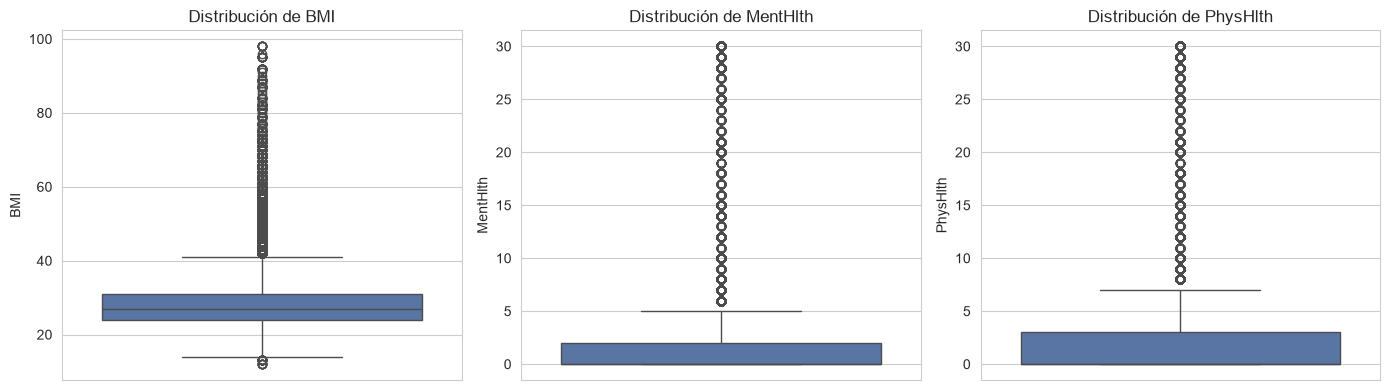

In [7]:
# Boxplots para detectar valores atípicos en variables continuas
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["BMI", "MentHlth", "PhysHlth"]):
    sns.boxplot(y=df[col], ax=ax, color="#4C72B0")
    ax.set_title(f"Distribución de {col}")
plt.tight_layout()
plt.show()

In [8]:
# Interpretación de los boxplots (calculada con los datos)
partes = []
for col in ["BMI", "MentHlth", "PhysHlth"]:
    s = df[col].dropna()
    q1, med, q3 = s.quantile([.25, .5, .75])
    lim = q3 + 1.5 * (q3 - q1)
    n = int((s > lim).sum())
    partes.append(f"{col}: mediana {med:.0f}, percentil 75 en {q3:.0f}, máximo {s.max():.0f}; "
                  f"{n:,} valores ({n/len(s)*100:.1f} %) por encima del límite IQR de {lim:.1f}")
print("INTERPRETACIÓN")
print("- " + "\n- ".join(partes))
con_ext = []
for c in ["BMI", "MentHlth", "PhysHlth"]:
    x = df[c].dropna(); a1, a3 = x.quantile([.25, .75])
    if (x > a3 + 1.5 * (a3 - a1)).any():
        con_ext.append(c)
print("Variables con valores por encima de la caja: " + (", ".join(con_ext) if con_ext else "ninguna") + ".")
if df["MentHlth"].median() <= 5 and df["PhysHlth"].median() <= 5:
    print("En MentHlth y PhysHlth la mayoría reporta pocos días de mala salud y una minoría reporta muchos.")
print("Los valores de BMI están dentro del rango válido declarado (12–98), por lo que no se consideran errores y se conservan.")

INTERPRETACIÓN
- BMI: mediana 27, percentil 75 en 31, máximo 98; 9,820 valores (3.9 %) por encima del límite IQR de 41.5
- MentHlth: mediana 0, percentil 75 en 2, máximo 30; 36,208 valores (14.3 %) por encima del límite IQR de 5.0
- PhysHlth: mediana 0, percentil 75 en 3, máximo 30; 40,949 valores (16.1 %) por encima del límite IQR de 7.5
Variables con valores por encima de la caja: BMI, MentHlth, PhysHlth.
En MentHlth y PhysHlth la mayoría reporta pocos días de mala salud y una minoría reporta muchos.
Los valores de BMI están dentro del rango válido declarado (12–98), por lo que no se consideran errores y se conservan.


In [9]:
# Se define df_clean antes de la limpieza para que el notebook se ejecute en orden
# (la celda de limpieza siguiente lo consulta antes de crearlo).
df_clean = df.copy()

## 4. Limpieza inicial

Para esta primera etapa se realizan tareas básicas de limpieza: eliminación de duplicados
(si existen), verificación de tipos de dato y creación de un dataframe de trabajo
(`df_clean`) que se usará en los siguientes cortes para la preparación de datos y el
modelado de clustering.

In [10]:
columnas_binarias = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
                      "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
                      "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"]
columnas_ordinales = ["GenHlth", "Age", "Education", "Income"]

print("Valores nulos por columna antes de la limpieza:")
for c in columnas_binarias + columnas_ordinales:
    n_nan = df_clean[c].isna().sum()
    if n_nan > 0:
        print(f"  {c}: {n_nan} valores nulos")

df_clean = df.drop_duplicates().copy()

filas_antes = df_clean.shape[0]
df_clean = df_clean.dropna(subset=columnas_binarias + columnas_ordinales).copy()
filas_despues_nulos = df_clean.shape[0]
print(f"\nFilas eliminadas por valores nulos: {filas_antes - filas_despues_nulos}")

for c in columnas_binarias + columnas_ordinales:
    df_clean[c] = df_clean[c].astype(int)

print(f"\nFilas antes de limpieza: {df.shape[0]:,}")
print(f"Filas después de limpieza: {df_clean.shape[0]:,}")
df_clean.dtypes

Valores nulos por columna antes de la limpieza:

Filas eliminadas por valores nulos: 0

Filas antes de limpieza: 253,680
Filas después de limpieza: 229,781


Diabetes_012            float64
HighBP                    int64
HighChol                  int64
CholCheck                 int64
BMI                     float64
Smoker                    int64
Stroke                    int64
HeartDiseaseorAttack      int64
PhysActivity              int64
Fruits                    int64
Veggies                   int64
HvyAlcoholConsump         int64
AnyHealthcare             int64
NoDocbcCost               int64
GenHlth                   int64
MentHlth                float64
PhysHlth                float64
DiffWalk                  int64
Sex                       int64
Age                       int64
Education                 int64
Income                    int64
dtype: object

## 5. Primeras visualizaciones

C:\Users\Victus\AppData\Local\Temp\ipykernel_7704\3637936748.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df_clean.iloc[:, 0], palette="Blues")


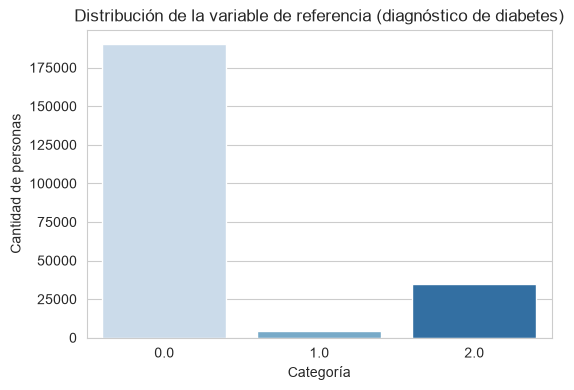

In [11]:
# Distribución de la variable de referencia (diagnóstico de diabetes)
plt.figure(figsize=(6, 4))
sns.countplot(x=df_clean.iloc[:, 0], palette="Blues")
plt.title("Distribución de la variable de referencia (diagnóstico de diabetes)")
plt.xlabel("Categoría")
plt.ylabel("Cantidad de personas")
plt.show()

In [12]:
# Interpretación: distribución de la variable de referencia
p = df_clean["Diabetes_012"].value_counts(normalize=True).sort_index() * 100
p.index = p.index.astype(int)
print("INTERPRETACIÓN")
print(f"La categoría 0 (sin diabetes) reúne {p.get(0, 0):.1f} % de los registros, la 1 (prediabetes) {p.get(1, 0):.1f} % "
      f"y la 2 (diabetes) {p.get(2, 0):.1f} %.")
if p.max() > 70:
    print("El desbalance es marcado. No afecta a K-means porque esta variable no se usa para agrupar, pero los "
          "porcentajes de la categoría más pequeña dentro de los clústeres serán poco estables por su tamaño.")
else:
    print("Las categorías están relativamente equilibradas.")

INTERPRETACIÓN
La categoría 0 (sin diabetes) reúne 82.7 % de los registros, la 1 (prediabetes) 2.0 % y la 2 (diabetes) 15.3 %.
El desbalance es marcado. No afecta a K-means porque esta variable no se usa para agrupar, pero los porcentajes de la categoría más pequeña dentro de los clústeres serán poco estables por su tamaño.


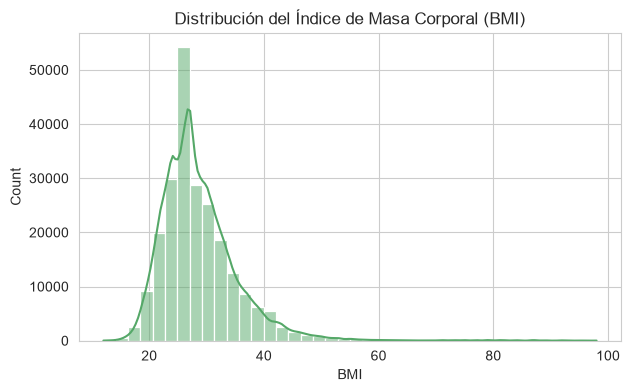

In [13]:
# Distribución del IMC (BMI)
plt.figure(figsize=(7, 4))
sns.histplot(df_clean["BMI"], bins=40, kde=True, color="#55A868")
plt.title("Distribución del Índice de Masa Corporal (BMI)")
plt.xlabel("BMI")
plt.show()

In [14]:
# Interpretación: distribución del BMI
s = df_clean["BMI"]
forma = "asimétrica a la derecha, con una cola larga de valores altos" if s.skew() > 0.5 else "aproximadamente simétrica"
print("INTERPRETACIÓN")
print(f"Promedio {s.mean():.1f}, mediana {s.median():.0f}, rango {s.min():.0f}–{s.max():.0f}, asimetría {s.skew():.2f}.")
print(f"La distribución es {forma}; el 50 % central de las personas tiene un BMI entre {s.quantile(.25):.0f} y {s.quantile(.75):.0f}. "
      "K-means es sensible a valores extremos, por eso se trabaja con variables escaladas y se conservan los valores "
      "extremos que están dentro del rango válido.")

INTERPRETACIÓN
Promedio 28.7, mediana 27, rango 12–98, asimetría 2.06.
La distribución es asimétrica a la derecha, con una cola larga de valores altos; el 50 % central de las personas tiene un BMI entre 24 y 32. K-means es sensible a valores extremos, por eso se trabaja con variables escaladas y se conservan los valores extremos que están dentro del rango válido.


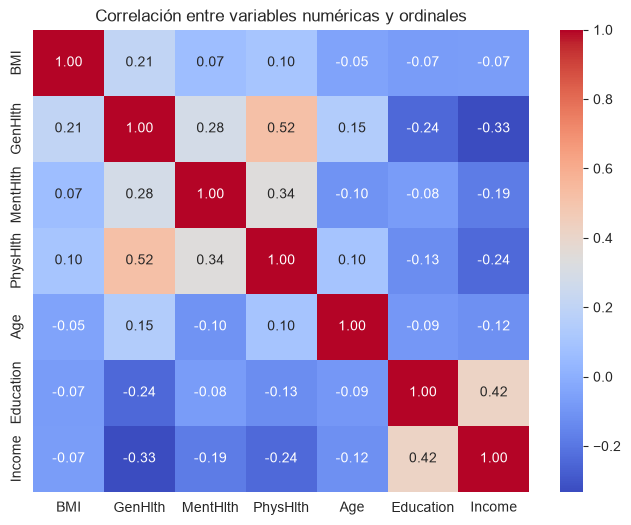

In [15]:
# Mapa de correlación entre variables numéricas/ordinales
variables_num = ["BMI", "GenHlth", "MentHlth", "PhysHlth", "Age", "Education", "Income"]
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[variables_num].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlación entre variables numéricas y ordinales")
plt.show()

In [16]:
# Interpretación: mapa de correlación
c = df_clean[variables_num].corr()
c = c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack()
top = c.reindex(c.abs().sort_values(ascending=False).index).head(3)
txt = "; ".join(f"{a} con {b} (r = {r:.2f})" for (a, b), r in top.items())
mx = c.abs().max()
print("INTERPRETACIÓN")
print(f"Las asociaciones más fuertes son: {txt}.")
print(f"Las correlaciones son {'débiles o moderadas' if mx < 0.6 else 'en algunos casos altas'} (máximo |r| = {mx:.2f}); "
      + ("no hay redundancia fuerte entre variables." if mx < 0.6 else "conviene revisar la redundancia entre las variables más correlacionadas."))

INTERPRETACIÓN
Las asociaciones más fuertes son: GenHlth con PhysHlth (r = 0.52); Education con Income (r = 0.42); MentHlth con PhysHlth (r = 0.34).
Las correlaciones son débiles o moderadas (máximo |r| = 0.52); no hay redundancia fuerte entre variables.


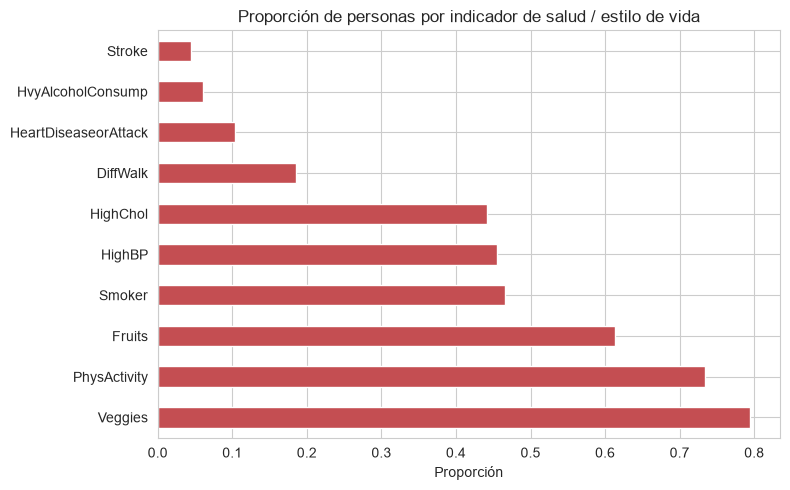

In [17]:
# Prevalencia de condiciones de salud e indicadores de estilo de vida
condiciones = ["HighBP", "HighChol", "Smoker", "Stroke", "HeartDiseaseorAttack",
               "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump", "DiffWalk"]

proporciones = df_clean[condiciones].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
proporciones.plot(kind="barh", color="#C44E52")
plt.title("Proporción de personas por indicador de salud / estilo de vida")
plt.xlabel("Proporción")
plt.tight_layout()
plt.show()

In [18]:
# Interpretación: prevalencia de indicadores
fmt = lambda s: ", ".join(f"{k} ({v:.2f})" for k, v in s.items())
print("INTERPRETACIÓN")
print(f"Indicadores más frecuentes: {fmt(proporciones.head(3))}. Menos frecuentes: {fmt(proporciones.tail(3))}.")
print("Los indicadores muy poco frecuentes varían poco entre personas, por lo que por sí solos aportan poco a "
      "separar grupos; su efecto depende de su combinación con las demás variables.")

INTERPRETACIÓN
Indicadores más frecuentes: Veggies (0.79), PhysActivity (0.73), Fruits (0.61). Menos frecuentes: HeartDiseaseorAttack (0.10), HvyAlcoholConsump (0.06), Stroke (0.04).
Los indicadores muy poco frecuentes varían poco entre personas, por lo que por sí solos aportan poco a separar grupos; su efecto depende de su combinación con las demás variables.


## 6. Bitácora de uso de IA
##Promt usado para apoyo y comparacion de informacion y organizacion

Estoy desarrollando un proyecto de minería de datos sobre segmentación de pacientes en riesgo de diabetes mediante clustering, usando el dataset
CDC Diabetes Health Indicators (BRFSS 2015, Kaggle/UCI), con 253.680 registros y 21 variables
(demográficas, de estilo de vida y clínicas autorreportadas: HighBP, HighChol, BMI, Smoker,
PhysActivity, GenHlth, Age, Income, etc.).

Quiero que revises y compares tu enfoque con el que ya tengo, para el primer corte, que incluye:
1. Descripción del dataset y diccionario de variables
2. Diagnóstico de calidad de datos (nulos, duplicados, rangos válidos, outliers)
3. Limpieza inicial
4. Primeras visualizaciones (distribuciones, correlaciones, prevalencia de indicadores)

Preguntas específicas:
- ¿Qué variables recomendarías priorizar o descartar para un clustering de perfiles de riesgo
  de diabetes, y por qué?
- ¿Qué técnica de preprocesamiento (escalado, codificación) sugerirías para esta mezcla de
  variables binarias, ordinales y continuas antes de aplicar K-Means?
- ¿Qué método(s) de clustering recomendarías para el siguiente corte, dado este tipo de datos?
- ¿Ves algún error conceptual o de calidad de datos que debería revisar?

Dame tu análisis independiente, sin asumir que mi enfoque actual es correcto.

## 7. Conclusión inicial

A partir de esta primera exploración, el conjunto de datos CDC Diabetes Health Indicators
es adecuado para un proyecto de clustering orientado a la segmentación de pacientes
según su riesgo de diabetes: cuenta con un volumen considerable de registros, variables
binarias de estilo de vida y condiciones de salud, y variables ordinales/continuas
(edad, percepción de salud general, IMC) que permiten construir perfiles diferenciados de
pacientes. El diagnóstico inicial de calidad de datos no evidenció valores nulos ni
duplicados relevantes, aunque sí será necesario, en el siguiente corte, revisar con más
detalle la escala de las variables (binarias vs. ordinales vs. continuas) antes de aplicar
los algoritmos de clustering, dado que estos son sensibles a la escala de las variables.


## 8. Preparación de datos para el modelado

La versión final de los datos para el EDA y el entrenamiento es `df_clean`, obtenida en la sección 4 (duplicados eliminados, filas con nulos eliminadas y variables binarias/ordinales convertidas a entero). Se eliminan los duplicados exactos para evitar que registros repetidos pesen más en el agrupamiento; como la encuesta no incluye un identificador, no se puede descartar que algunos correspondan a personas distintas con respuestas idénticas, lo cual se reconoce como limitación. Los valores atípicos de `BMI` se conservan porque están dentro del rango válido declarado (12–98) y corresponden a personas reales de la encuesta.

### 8.1 Selección de variables para el clustering
Se incluyen variables de condición de salud, hábitos y percepción de salud. Se excluyen:
- `Diabetes_012`: variable de referencia; usarla para agrupar sesgaría los grupos hacia el diagnóstico (fuga de información).
- `CholCheck`, `AnyHealthcare`, `NoDocbcCost`: describen acceso a servicios de salud, no condición ni hábitos.
- `Education`, `Income`, `Sex`: variables demográficas que se usan solo para caracterizar los grupos.

In [19]:
VARS_CLUSTER = ["HighBP", "HighChol", "BMI", "Smoker", "Stroke", "HeartDiseaseorAttack",
                "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump",
                "GenHlth", "MentHlth", "PhysHlth", "DiffWalk", "Age"]
print(f"Variables usadas para agrupar ({len(VARS_CLUSTER)}):", VARS_CLUSTER)

Variables usadas para agrupar (15): ['HighBP', 'HighChol', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Age']


### 8.2 Escalamiento
K-means usa distancias, por lo que se aplica `StandardScaler` para que variables con escalas distintas (BMI, MentHlth, PhysHlth frente a las binarias 0/1) tengan peso comparable. Todas las variables son numéricas, por lo que no se requiere codificación adicional.

In [20]:
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(df_clean[VARS_CLUSTER])
print("Matriz escalada:", X_scaled.shape)

Matriz escalada: (229781, 15)


## 9. Análisis exploratorio orientado a la pregunta del proyecto

### 9.1 ¿Cómo se distribuye la variable de referencia y existe desbalance?

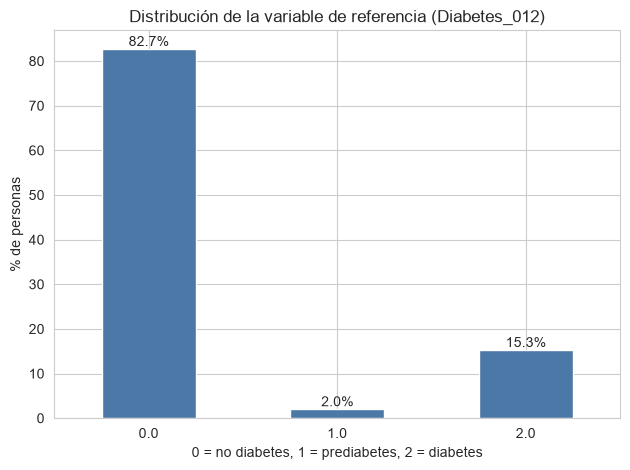

In [21]:
conteo = df_clean["Diabetes_012"].value_counts(normalize=True).sort_index() * 100
ax = conteo.plot(kind="bar", color="#4C78A8")
ax.set(title="Distribución de la variable de referencia (Diabetes_012)",
       xlabel="0 = no diabetes, 1 = prediabetes, 2 = diabetes", ylabel="% de personas")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

In [22]:
p = df_clean["Diabetes_012"].value_counts(normalize=True).sort_index() * 100
p.index = p.index.astype(int)
print("INTERPRETACIÓN")
print(f"Sin diabetes: {p.get(0, 0):.1f} %, prediabetes: {p.get(1, 0):.1f} %, diabetes: {p.get(2, 0):.1f} %.")
print("El desbalance se tiene en cuenta al leer los perfiles de los clústeres, pero no condiciona el agrupamiento "
      "porque esta variable no participa en él." if p.max() > 70 else "Las categorías están relativamente equilibradas.")

INTERPRETACIÓN
Sin diabetes: 82.7 %, prediabetes: 2.0 %, diabetes: 15.3 %.
El desbalance se tiene en cuenta al leer los perfiles de los clústeres, pero no condiciona el agrupamiento porque esta variable no participa en él.


### 9.2 ¿Hay valores atípicos en el IMC y cambia entre categorías de referencia?

BMI por encima de 44.0: 5,638 (2.5%)


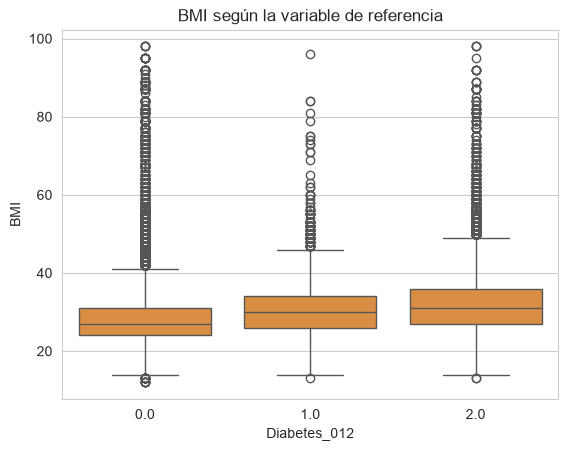

In [23]:
q1, q3 = df_clean["BMI"].quantile([.25, .75]); iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr
n_out = (df_clean["BMI"] > lim_sup).sum()
print(f"BMI por encima de {lim_sup:.1f}: {n_out:,} ({n_out/len(df_clean)*100:.1f}%)")

sns.boxplot(data=df_clean, x="Diabetes_012", y="BMI", color="#F28E2B")
plt.title("BMI según la variable de referencia"); plt.show()

In [24]:
med = df_clean.groupby("Diabetes_012")["BMI"].median()
med.index = med.index.astype(int)
print("INTERPRETACIÓN")
print("Mediana de BMI por categoría: " + ", ".join(f"{k}: {v:.0f}" for k, v in med.items())
      + f". Valores por encima del límite IQR ({lim_sup:.1f}): {n_out:,} ({n_out/len(df_clean)*100:.1f} %).")
if med.get(2, 0) > med.get(0, 0):
    print("El BMI tiende a ser mayor en las personas con diabetes que en las que no la reportan; es una asociación "
          "observada y no implica que el BMI cause la enfermedad.")
else:
    print("No se observa un BMI mayor en las personas con diabetes respecto a las que no la reportan.")
print("Los atípicos están dentro del rango válido (12–98), por lo que se conservan.")

INTERPRETACIÓN
Mediana de BMI por categoría: 0: 27, 1: 30, 2: 31. Valores por encima del límite IQR (44.0): 5,638 (2.5 %).
El BMI tiende a ser mayor en las personas con diabetes que en las que no la reportan; es una asociación observada y no implica que el BMI cause la enfermedad.
Los atípicos están dentro del rango válido (12–98), por lo que se conservan.


### 9.3 ¿Qué indicadores de salud son más frecuentes en cada categoría de referencia?

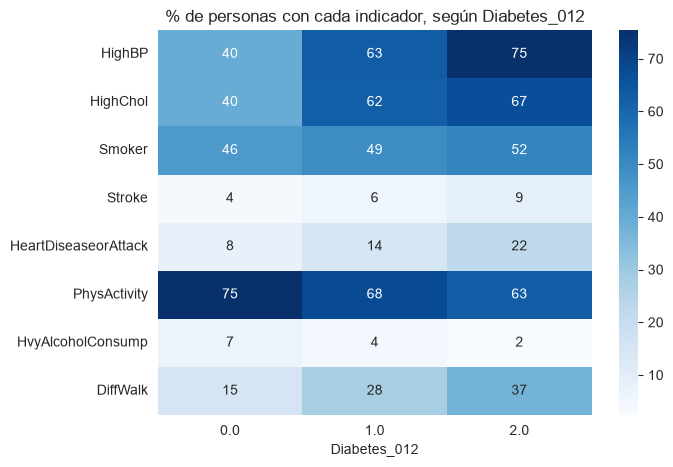

In [25]:
indic = ["HighBP", "HighChol", "Smoker", "Stroke", "HeartDiseaseorAttack",
         "PhysActivity", "HvyAlcoholConsump", "DiffWalk"]
tabla = df_clean.groupby("Diabetes_012")[indic].mean().T * 100
plt.figure(figsize=(7, 5))
sns.heatmap(tabla, annot=True, fmt=".0f", cmap="Blues")
plt.title("% de personas con cada indicador, según Diabetes_012")
plt.show()

In [26]:
t = tabla.copy(); t.columns = t.columns.astype(int)
dif = (t[2] - t[0]).sort_values(ascending=False)
sube = ", ".join(f"{k} ({v:+.1f} puntos porcentuales)" for k, v in dif.head(3).items())
baja = dif.tail(1)
print("INTERPRETACIÓN")
print(f"Los indicadores que más aumentan en el grupo con diabetes frente al grupo sin diabetes son: {sube}.")
if baja.iloc[0] < -2:
    print(f"El único indicador que disminuye de forma notable es {baja.index[0]} ({baja.iloc[0]:+.1f} puntos porcentuales).")
print("Son asociaciones observadas en datos autorreportados, no relaciones causales.")

INTERPRETACIÓN
Los indicadores que más aumentan en el grupo con diabetes frente al grupo sin diabetes son: HighBP (+35.7 puntos porcentuales), HighChol (+27.4 puntos porcentuales), DiffWalk (+22.5 puntos porcentuales).
El único indicador que disminuye de forma notable es PhysActivity (-12.6 puntos porcentuales).
Son asociaciones observadas en datos autorreportados, no relaciones causales.


### 9.4 ¿Qué variables de agrupamiento están correlacionadas?

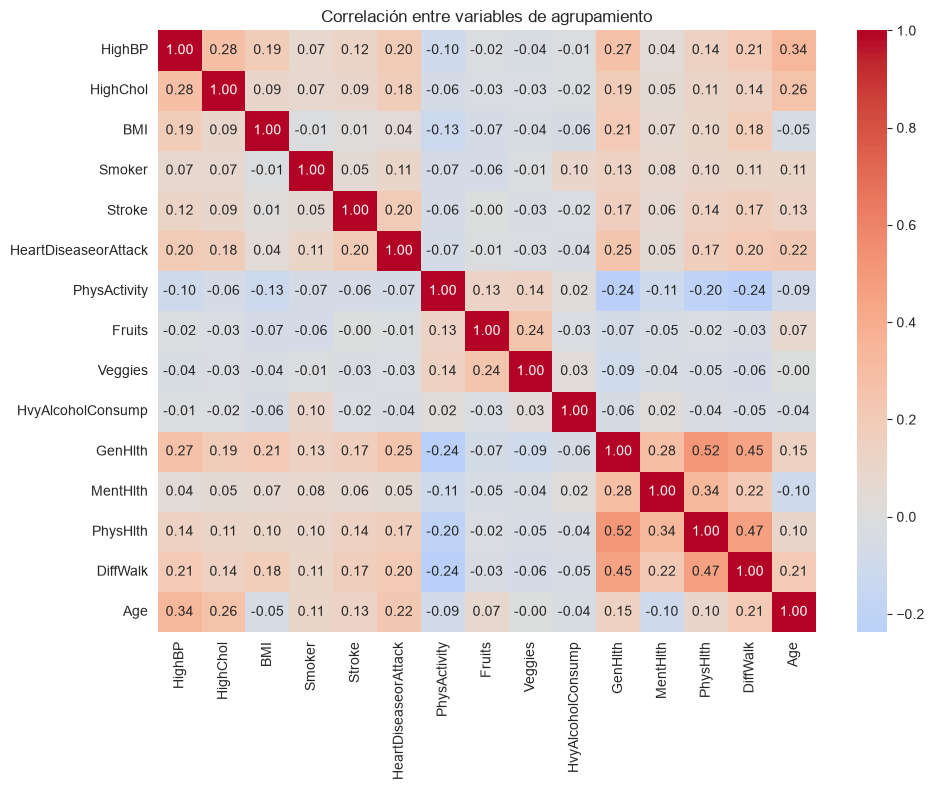

In [27]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean[VARS_CLUSTER].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre variables de agrupamiento")
plt.tight_layout(); plt.show()

In [28]:
cc = df_clean[VARS_CLUSTER].corr()
cc = cc.where(np.triu(np.ones(cc.shape), k=1).astype(bool)).stack()
top9 = cc.reindex(cc.abs().sort_values(ascending=False).index).head(3)
txt = "; ".join(f"{a} con {b} (r = {r:.2f})" for (a, b), r in top9.items())
mx = cc.abs().max()
print("INTERPRETACIÓN")
print(f"Las relaciones más claras son: {txt}.")
print("Las variables más correlacionadas entre sí tendrán un peso conjunto mayor en la formación de los grupos. " + ("Ningún par es tan redundante como para justificar excluir una variable."
      if mx < 0.6 else "Algunos pares son altamente correlacionados y podrían ser redundantes."))

INTERPRETACIÓN
Las relaciones más claras son: GenHlth con PhysHlth (r = 0.52); PhysHlth con DiffWalk (r = 0.47); GenHlth con DiffWalk (r = 0.45).
Las variables más correlacionadas entre sí tendrán un peso conjunto mayor en la formación de los grupos. Ningún par es tan redundante como para justificar excluir una variable.


## 10. Exploración del número de clústeres (codo y silueta)

Se prueban valores de k entre 2 y 8. La silueta se calcula sobre una muestra aleatoria de 10.000 registros para reducir el costo computacional.

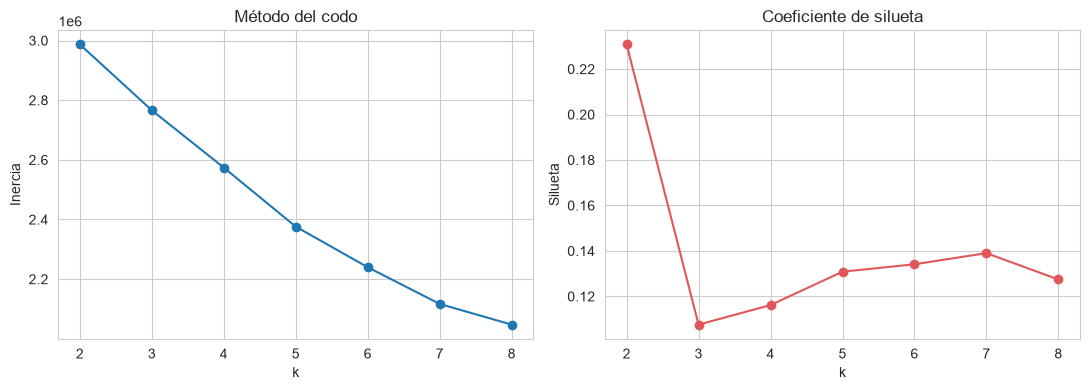

,k,inercia,silueta
0,2,2986815.280,0.231
1,3,2765909.752,0.108
2,4,2573791.328,0.116
3,5,2375945.016,0.131
4,6,2239809.727,0.134
5,7,2116759.227,0.139
6,8,2047373.914,0.127


In [29]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas = km.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, etiquetas, sample_size=10000, random_state=42)
    resultados.append({"k": k, "inercia": km.inertia_, "silueta": sil})
res_k = pd.DataFrame(resultados)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(res_k["k"], res_k["inercia"], marker="o")
ax[0].set(title="Método del codo", xlabel="k", ylabel="Inercia")
ax[1].plot(res_k["k"], res_k["silueta"], marker="o", color="#E15759")
ax[1].set(title="Coeficiente de silueta", xlabel="k", ylabel="Silueta")
plt.tight_layout(); plt.show()
res_k.round(3)

In [30]:
# Selección de k: mayor silueta entre k = 3 y k = 6
cand = res_k[(res_k["k"] >= 3) & (res_k["k"] <= 6)]
K_FINAL = int(cand.loc[cand["silueta"].idxmax(), "k"])
s_best = float(res_k.loc[res_k["k"] == K_FINAL, "silueta"].iloc[0])
nivel = "baja" if s_best < 0.25 else ("moderada" if s_best < 0.5 else "alta")
inr = res_k["inercia"].values
red_ini = (inr[0] - inr[1]) / inr[0] * 100
red_fin = (inr[-2] - inr[-1]) / inr[-2] * 100
print("INTERPRETACIÓN Y SELECCIÓN DE k")
print(f"La inercia baja de {inr[0]:,.0f} (k=2) a {inr[-1]:,.0f} (k=8); la reducción relativa pasa de {red_ini:.1f} % "
      f"entre k=2 y k=3 a {red_fin:.1f} % entre k=7 y k=8" + (", es decir, cada aumento de k aporta menos." if red_ini > red_fin else "."))
print(f"La silueta varía entre {res_k['silueta'].min():.3f} y {res_k['silueta'].max():.3f}. "
      f"Entre k=3 y k=6 el valor más alto es el de k={K_FINAL} ({s_best:.3f}), considerado {nivel}"
      + (": los grupos se solapan." if nivel == "baja" else "."))
print(f"Se selecciona k={K_FINAL}: tiene la mayor silueta en ese rango; se descarta k=2 por ser una partición "
      "demasiado gruesa para describir perfiles diferenciados y k>6 porque dificulta la interpretación de los grupos.")

INTERPRETACIÓN Y SELECCIÓN DE k
La inercia baja de 2,986,815 (k=2) a 2,047,374 (k=8); la reducción relativa pasa de 7.4 % entre k=2 y k=3 a 3.3 % entre k=7 y k=8, es decir, cada aumento de k aporta menos.
La silueta varía entre 0.108 y 0.231. Entre k=3 y k=6 el valor más alto es el de k=6 (0.134), considerado baja: los grupos se solapan.
Se selecciona k=6: tiene la mayor silueta en ese rango; se descarta k=2 por ser una partición demasiado gruesa para describir perfiles diferenciados y k>6 porque dificulta la interpretación de los grupos.


## 11. Modelo final, tamaño y perfil de los clústeres

In [31]:
print("k seleccionado en la sección 10:", K_FINAL)

km_final = KMeans(n_clusters=K_FINAL, n_init=10, random_state=42).fit(X_scaled)
df_clean["cluster"] = km_final.labels_

tamano = df_clean["cluster"].value_counts().sort_index()
pd.DataFrame({"registros": tamano, "porcentaje": (tamano / len(df_clean) * 100).round(1)})

k seleccionado en la sección 10: 6


,registros,porcentaje
cluster,,
0,34994,15.2
1,29579,12.9
2,82117,35.7
3,13313,5.8
4,10247,4.5
5,59531,25.9


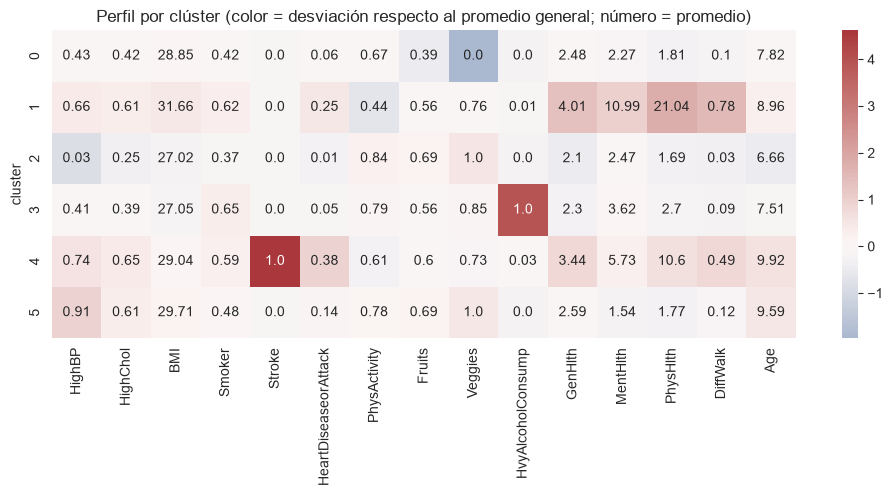

,HighBP,HighChol,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,GenHlth,MentHlth,PhysHlth,DiffWalk,Age
cluster,,,,,,,,,,,,,,,
0,0.43,0.42,28.85,0.42,0.0,0.06,0.67,0.39,0.00,0.00,2.48,2.27,1.81,0.10,7.82
1,0.66,0.61,31.66,0.62,0.0,0.25,0.44,0.56,0.76,0.01,4.01,10.99,21.04,0.78,8.96
2,0.03,0.25,27.02,0.37,0.0,0.01,0.84,0.69,1.00,0.00,2.10,2.47,1.69,0.03,6.66
3,0.41,0.39,27.05,0.65,0.0,0.05,0.79,0.56,0.85,1.00,2.30,3.62,2.70,0.09,7.51
4,0.74,0.65,29.04,0.59,1.0,0.38,0.61,0.60,0.73,0.03,3.44,5.73,10.60,0.49,9.92
5,0.91,0.61,29.71,0.48,0.0,0.14,0.78,0.69,1.00,0.00,2.59,1.54,1.77,0.12,9.59


In [32]:
perfil = df_clean.groupby("cluster")[VARS_CLUSTER].mean()
z = (perfil - df_clean[VARS_CLUSTER].mean()) / df_clean[VARS_CLUSTER].std()

plt.figure(figsize=(12, 4))
sns.heatmap(z, annot=perfil.round(2), fmt="", cmap="vlag", center=0)
plt.title("Perfil por clúster (color = desviación respecto al promedio general; número = promedio)")
plt.show()
perfil.round(2)

In [33]:
# Referencia descriptiva (NO es accuracy): composición de Diabetes_012 dentro de cada clúster
ref = pd.crosstab(df_clean["cluster"], df_clean["Diabetes_012"], normalize="index") * 100
ref.round(1)

Diabetes_012,0.0,1.0,2.0
cluster,,,
0,83.9,2.0,14.1
1,64.5,3.2,32.3
2,94.2,1.1,4.7
3,93.1,1.4,5.4
4,65.5,2.6,31.9
5,75.9,2.7,21.4


In [34]:
# Variables demográficas excluidas del agrupamiento, usadas solo para caracterizar
df_clean.groupby("cluster")[["Sex", "Education", "Income"]].mean().round(2)

,Sex,Education,Income
cluster,,,
0,0.52,4.82,5.72
1,0.37,4.58,4.47
2,0.41,5.19,6.42
3,0.45,5.15,6.55
4,0.45,4.68,4.75
5,0.47,5.00,6.02


In [35]:
# Descripción de los grupos a partir de lo observado (sin etiquetas clínicas)
filas = []
for g in z.index:
    top = z.loc[g].abs().sort_values(ascending=False).head(3).index
    desc = ", ".join(("mayor " if z.loc[g, v] > 0 else "menor ") + v for v in top)
    filas.append({"Grupo": g, "Registros": int(tamano[g]),
                  "% del total": round(tamano[g] / len(df_clean) * 100, 1),
                  "Variables que más se alejan del promedio": desc})
descripcion_clusters = pd.DataFrame(filas)

r2 = ref[2.0] if 2.0 in ref.columns else ref[2]
print("INTERPRETACIÓN")
print("Los grupos se describen por las variables que más se alejan del promedio general (ver tabla). Los números de "
      "grupo son identificadores arbitrarios y no representan categorías conocidas previamente.")
print(f"El porcentaje de personas con diabetes (categoría 2) va de {r2.min():.1f} % a {r2.max():.1f} % según el grupo; "
      "esta composición es solo descriptiva y no es una medida de acierto del agrupamiento.")
descripcion_clusters

INTERPRETACIÓN
Los grupos se describen por las variables que más se alejan del promedio general (ver tabla). Los números de grupo son identificadores arbitrarios y no representan categorías conocidas previamente.
El porcentaje de personas con diabetes (categoría 2) va de 4.7 % a 32.3 % según el grupo; esta composición es solo descriptiva y no es una medida de acierto del agrupamiento.


,Grupo,Registros,% del total,Variables que más se alejan del promedio
0,0,34994,15.2,"menor Veggies, menor Fruits, menor PhysHlth"
1,1,29579,12.9,"mayor PhysHlth, mayor DiffWalk, mayor GenHlth"
2,2,82117,35.7,"menor HighBP, mayor Veggies, menor GenHlth"
3,3,13313,5.8,"mayor HvyAlcoholConsump, mayor Smoker, menor G..."
4,4,10247,4.5,"mayor Stroke, mayor HeartDiseaseorAttack, mayo..."
5,5,59531,25.9,"mayor HighBP, mayor Veggies, mayor Age"


## 12. Visualización de los grupos y estabilidad

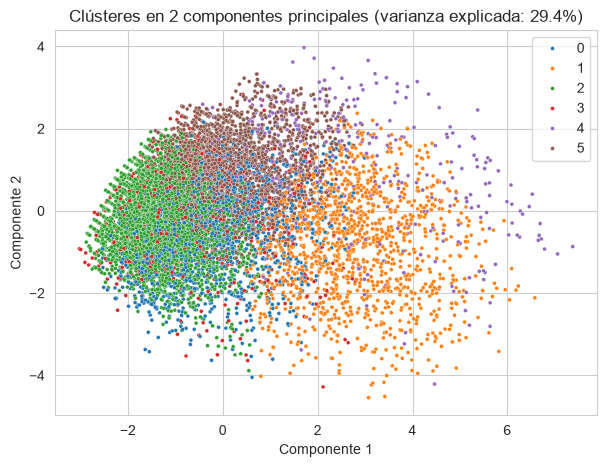

Estabilidad (ARI entre dos semillas): 0.996


In [36]:
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
idx = np.random.RandomState(42).choice(len(coords), 10000, replace=False)

plt.figure(figsize=(7, 5))
sns.scatterplot(x=coords[idx, 0], y=coords[idx, 1],
                hue=df_clean["cluster"].values[idx], palette="tab10", s=8)
plt.title(f"Clústeres en 2 componentes principales (varianza explicada: {pca.explained_variance_ratio_.sum()*100:.1f}%)")
plt.xlabel("Componente 1"); plt.ylabel("Componente 2")
plt.show()

km_alt = KMeans(n_clusters=K_FINAL, n_init=10, random_state=7).fit(X_scaled)
ari = adjusted_rand_score(km_final.labels_, km_alt.labels_)
print("Estabilidad (ARI entre dos semillas):", round(ari, 3))

In [37]:
var_exp = pca.explained_variance_ratio_.sum() * 100
est = "muy estable" if ari >= 0.9 else ("estable" if ari >= 0.7 else "poco estable")
print("INTERPRETACIÓN")
print(f"Los dos primeros componentes explican {var_exp:.1f} % de la varianza, por lo que la gráfica es solo una vista "
      "parcial de la separación entre grupos; los puntos que parecen mezclarse en 2 dimensiones pueden separarse en las "
      "demás dimensiones.")
print(f"El ARI entre dos semillas es {ari:.3f}: la partición es {est} frente al azar de la inicialización.")

INTERPRETACIÓN
Los dos primeros componentes explican 29.4 % de la varianza, por lo que la gráfica es solo una vista parcial de la separación entre grupos; los puntos que parecen mezclarse en 2 dimensiones pueden separarse en las demás dimensiones.
El ARI entre dos semillas es 0.996: la partición es muy estable frente al azar de la inicialización.


## 13. Conclusiones del segundo avance

In [38]:
dist = df_clean["Diabetes_012"].value_counts(normalize=True).sort_index() * 100
dist.index = dist.index.astype(int)
a, b = list(top9.index[0])
mejor_ind = ", ".join(dif.head(2).index)
tam = ", ".join(f"grupo {g}: {n:,}" for g, n in tamano.items())

print("1. Principales hallazgos del EDA:")
print(f"   - La variable de referencia está desbalanceada: sin diabetes {dist.get(0, 0):.1f} %, "
      f"prediabetes {dist.get(1, 0):.1f} %, diabetes {dist.get(2, 0):.1f} %.")
print(f"   - Mediana de BMI por categoría: " + ", ".join(f"{k}: {v:.0f}" for k, v in med.items()) + ".")
print(f"   - Los indicadores que más aumentan en el grupo con diabetes son {mejor_ind}.")
print(f"   - La correlación más alta entre variables de agrupamiento es {a} con {b} (r = {top9.iloc[0]:.2f}).")
print()
print("2. Solución con resultados más adecuados:")
print(f"   K-means con k={K_FINAL} sobre {len(VARS_CLUSTER)} variables escaladas; tamaños: {tam}.")
print()
print("3. Evidencias que respaldan la selección:")
print(f"   - Silueta de {s_best:.3f} ({nivel}), la más alta entre k=3 y k=6.")
print(f"   - La reducción relativa de la inercia pasa de {red_ini:.1f} % (k=2 a 3) a {red_fin:.1f} % (k=7 a 8).")
print(f"   - ARI entre semillas de {ari:.3f} ({est}) y perfiles descritos en la sección 11.")
print()
print("4. Errores y limitaciones:")
print("   - K-means usa distancias euclidianas y la mayoría de las variables son binarias u ordinales, lo que limita la calidad de la partición.")
print("   - Los datos son autorreportados y provienen de una encuesta de 2015, sin identificador de persona.")
print("   - La silueta se calculó sobre una muestra de 10.000 registros y el PCA explica solo una parte de la varianza.")
print("   - La variable de referencia solo describe los grupos; no valida ni mide el acierto del agrupamiento.")
if s_best < 0.25:
    print("   - La silueta es baja: los grupos se solapan y deben interpretarse como perfiles tendenciales, no como categorías separadas.")

1. Principales hallazgos del EDA:
   - La variable de referencia está desbalanceada: sin diabetes 82.7 %, prediabetes 2.0 %, diabetes 15.3 %.
   - Mediana de BMI por categoría: 0: 27, 1: 30, 2: 31.
   - Los indicadores que más aumentan en el grupo con diabetes son HighBP, HighChol.
   - La correlación más alta entre variables de agrupamiento es GenHlth con PhysHlth (r = 0.52).

2. Solución con resultados más adecuados:
   K-means con k=6 sobre 15 variables escaladas; tamaños: grupo 0: 34,994, grupo 1: 29,579, grupo 2: 82,117, grupo 3: 13,313, grupo 4: 10,247, grupo 5: 59,531.

3. Evidencias que respaldan la selección:
   - Silueta de 0.134 (baja), la más alta entre k=3 y k=6.
   - La reducción relativa de la inercia pasa de 7.4 % (k=2 a 3) a 3.3 % (k=7 a 8).
   - ARI entre semillas de 0.996 (muy estable) y perfiles descritos en la sección 11.

4. Errores y limitaciones:
   - K-means usa distancias euclidianas y la mayoría de las variables son binarias u ordinales, lo que limita la cali

In [39]:
import json, joblib, sklearn, numpy, pandas
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

pipe = Pipeline([("scaler", StandardScaler()), ("kmeans", KMeans(n_clusters=K_FINAL, n_init=10, random_state=42))])
df_clean["cluster"] = pipe.fit_predict(df_clean[VARS_CLUSTER])
joblib.dump(pipe, "pipeline_clustering.joblib")

mg, sg = df_clean[VARS_CLUSTER].mean(), df_clean[VARS_CLUSTER].std()
perfil = df_clean.groupby("cluster")[VARS_CLUSTER].mean()
z = (perfil - mg) / sg
tam = df_clean["cluster"].value_counts().sort_index()
diab = df_clean.assign(d=df_clean["Diabetes_012"] == 2).groupby("cluster")["d"].mean() * 100

clusters = {str(int(g)): {
    "registros": int(tam[g]),
    "porcentaje": round(float(tam[g] / len(df_clean) * 100), 1),
    "pct_diabetes_referencia": round(float(diab[g]), 1),
    "descripcion": [("mayor " if z.loc[g, v] > 0 else "menor ") + v for v in z.loc[g].abs().nlargest(3).index],
    "promedios": {v: round(float(perfil.loc[g, v]), 3) for v in VARS_CLUSTER}} for g in perfil.index}

meta = {"k": int(K_FINAL), "variables": list(VARS_CLUSTER),
        "rangos": {v: [float(df_clean[v].min()), float(df_clean[v].max())] for v in VARS_CLUSTER},
        "promedio_global": {v: round(float(mg[v]), 3) for v in VARS_CLUSTER}, "clusters": clusters}
json.dump(meta, open("metadatos_clustering.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

open("requirements.txt", "w").write(f"streamlit>=1.35\nscikit-learn=={sklearn.__version__}\njoblib=={joblib.__version__}\nnumpy=={numpy.__version__}\npandas=={pandas.__version__}\n")
casos = df_clean.groupby("cluster").head(1).sort_values("cluster")[VARS_CLUSTER + ["cluster"]]
casos.to_csv("casos_consistencia.csv", index=False)
casos

,HighBP,HighChol,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,GenHlth,MentHlth,PhysHlth,DiffWalk,Age,cluster
1,0,0,25.0,1,0,0,1,0,0,0,3,0.0,0.0,0,7,0
0,1,1,40.0,1,0,0,0,0,1,0,5,18.0,15.0,1,9,1
9,0,0,24.0,0,0,0,0,0,1,0,2,0.0,0.0,0,8,2
19,0,1,28.0,0,0,0,0,0,0,1,2,10.0,0.0,0,4,3
14,0,1,33.0,1,1,0,1,0,1,0,4,30.0,28.0,0,4,4
3,1,0,27.0,0,0,0,1,1,1,0,2,0.0,0.0,0,11,5


In [40]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Excluir variables objetivo/referencia para hacer clustering no supervisado
cols_excluir = [
    col for col in ["Diabetes_012", "Diabetes_binary"] if col in df_clean.columns
]
X_raw = df_clean.drop(columns=cols_excluir).copy()

# Escalar variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print("Variables usadas para clustering:", list(X_raw.columns))
print("Forma de X_scaled:", X_scaled.shape)

Variables usadas para clustering: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income', 'cluster']
Forma de X_scaled: (229781, 22)


k=2 -> Inercia: 4534399.20 | Silueta (muestra): 0.1857
k=3 -> Inercia: 4193524.80 | Silueta (muestra): 0.1014
k=4 -> Inercia: 3974574.51 | Silueta (muestra): 0.1049
k=5 -> Inercia: 3769415.91 | Silueta (muestra): 0.1167
k=6 -> Inercia: 3570667.87 | Silueta (muestra): 0.1260


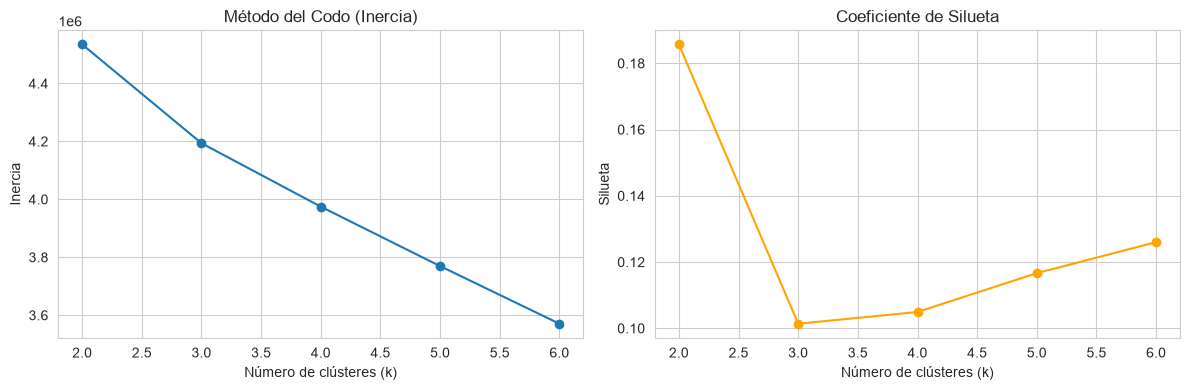

In [41]:
k_values = [2, 3, 4, 5, 6]
inercias = []
siluetas = []

# Muestra para calcular silueta rápido y reproducible
rng = np.random.default_rng(42)
idx_muestra = rng.choice(len(X_scaled), size=min(20000, len(X_scaled)), replace=False)
X_muestra = X_scaled[idx_muestra]

for k in k_values:
  modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
  modelo.fit(X_scaled)
  inercias.append(modelo.inertia_)

  etiquetas_muestra = modelo.predict(X_muestra)
  sil = silhouette_score(X_muestra, etiquetas_muestra)
  siluetas.append(sil)
  print(f"k={k} -> Inercia: {modelo.inertia_:.2f} | Silueta (muestra): {sil:.4f}")

# Gráficos de Inercia y Silueta
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_values, inercias, marker="o")
axes[0].set_title("Método del Codo (Inercia)")
axes[0].set_xlabel("Número de clústeres (k)")
axes[0].set_ylabel("Inercia")

axes[1].plot(k_values, siluetas, marker="o", color="orange")
axes[1].set_title("Coeficiente de Silueta")
axes[1].set_xlabel("Número de clústeres (k)")
axes[1].set_ylabel("Silueta")

plt.tight_layout()
plt.show()

In [42]:
k_final = 3  # Ajusta según tu elección justificada

kmeans_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
df_clean["Cluster"] = kmeans_final.fit_predict(X_scaled)

# Tamaño y porcentaje de cada clúster
resumen_tamano = pd.DataFrame({
    "Registros": df_clean["Cluster"].value_counts().sort_index(),
    "Porcentaje (%)": (
        df_clean["Cluster"].value_counts(normalize=True).sort_index() * 100
    ).round(2),
})
print("=== Tamaño de los clústeres ===")
print(resumen_tamano)

# Promedios por clúster (incluyendo variables de referencia para describir)
print("\n=== Promedios por clúster ===")
perfil_clusters = df_clean.groupby("Cluster").mean(numeric_only=True).round(2)
display(perfil_clusters.T)

# Distribución de Diabetes_012 dentro de cada clúster (si existe)
if "Diabetes_012" in df_clean.columns:
  print("\n=== Proporción de Diabetes_012 por clúster (%) ===")
  cruce_diabetes = (
      pd.crosstab(df_clean["Cluster"], df_clean["Diabetes_012"], normalize="index")
      * 100
  ).round(2)
  display(cruce_diabetes)

=== Tamaño de los clústeres ===
         Registros  Porcentaje (%)
Cluster                           
0           118158           51.42
1            67936           29.57
2            43687           19.01

=== Promedios por clúster ===


Cluster,0,1,2
Diabetes_012,0.13,0.44,0.68
HighBP,0.11,0.91,0.69
HighChol,0.28,0.61,0.62
CholCheck,0.94,0.99,0.98
BMI,27.26,29.50,31.29
Smoker,0.39,0.50,0.62
Stroke,0.00,0.07,0.12
HeartDiseaseorAttack,0.02,0.15,0.27
PhysActivity,0.82,0.78,0.44
Fruits,0.61,0.68,0.51



=== Proporción de Diabetes_012 por clúster (%) ===


Diabetes_012,0.0,1.0,2.0
Cluster,,,
0,92.99,1.20,5.81
1,76.52,2.66,20.82
2,64.55,3.20,32.25


In [43]:
joblib.dump(scaler, "scaler_kmeans.joblib")
joblib.dump(kmeans_final, "modelo_kmeans.joblib")

# Prueba de consistencia con la primera fila de X_raw
registro_ejemplo = X_raw.iloc[[0]]
pred_ejemplo = kmeans_final.predict(scaler.transform(registro_ejemplo))[0]
print("Clúster asignado al registro 0:", pred_ejemplo)

Clúster asignado al registro 0: 2
